# 1-board: opamp-temperature

Measure how the current chain's gain and zero move with board temperature, so a current read on a warm board is known to the right fraction and the winding thermometer's ratio is not reading the amplifier.

## Purpose

The winding thermometer reads the motor's resistance as a ratio to a reference taken at the start of a hold, and copper's resistance rises about 0.39 % per degree. A gain that drifts while the board warms through the hold reads as winding temperature. The current limit and every stall decision are in amperes through the same gain. The current-scale experiment graded that gain at room, 1135.0 +/- 1.2 counts per amp with an in-drive offset of +5.3 counts, and this experiment runs the same DC laps at four board temperatures and fits the gain and the zero at each. The temperature coefficient, the tempco, is the slope of those gains against the board NTC read through the ntc-curve result.

The ntc-curve experiment left one question for this capture, whether the board's own heat under drive moves the NTC. Every lap here carries a torque-off rest before its driven segments and the NTC in every row, so the last section reads that off the same data.

## Procedure

The board is taped with kapton to the heated bed of a Prusa MK3S printer with the steel sheet off, as in ntc-curve, with a small air gap under it at the connector pins. The board runs on the DPS and the experiment image. The DMM is on DC A through its 20 A jack, in series with the bare 5 ohm load, MOT_A to the meter, the meter to the load, the load to MOT_B, with the meter at room. At each plateau `capture.py` runs one lap per rail level, 3.7, 4.5, 5.5, 7.2 and 7.6 V, both directions at 100 % duty, with the rail trimmed to the level before each lap, and every row carries the board NTC.

One deviation from the written procedure. The power resistor's leads were too short to hang it off the bed, so the load sat on the heated bed through the whole run. The load's resistance rises with its temperature, so the current at a given level fell about 1 % at the warm and hot plateaus against room. The fit is counts against the meter's amps, so the load's value drops out of the gain and only the x axis moves. The load dissipates up to 9 W during a lap, about 3 s per segment, on a bed that is either off or held by its thermostat, and the last section looks for its heat in the NTC.

1. The board and the bed as above, the bed off but still warm from the ntc-curve run earlier in the sitting. The DMM on DC A, Bluetooth on.
2. `capture.py`. It marks `room` and runs the laps, then asks for the heater at each prompt. The bed went to 60 C after the room laps, the `warm` mark came ten minutes later, the bed went to 80 C after the warm laps, the `hot` mark eight minutes after that, and the bed went off after the hot laps.
3. The `room again` mark came 25 minutes after the bed went off, with the NTC back near the room reading, before the full cool-down.

The plateau names are labels. The NTC in every row is the temperature, and the bed's own thermistor sits in the heater under the air gap and reads the heater, so its log is kept as a side note on the rig and never as a reference.

## Data

- `<plateau>/levels.csv`: one row per lap, `k`, `volts_set` the rail level asked for, `dps_read`, `vsys_read` the rail the board read at rest, `t_start` and `t_end` the host time of the sweep, `folder`.
- `<plateau>/laps/<k>/sweep.csv`, `meta.json`: the rest and the two laps at that level, one row per control tick at 20 kHz. Segment 0 is the one second torque-off rest, 1 and 2 the two directions of three seconds each with a two second rest between them that is not streamed. `current_raw`, `vmotor_a`, `vmotor_b`, `vbus_raw` and `ntc_raw` are ADC counts.
- `dmm.csv`: the meter through the run, `t_host`, `function` (`DC A` throughout), `value` in amps, `raw` the packet.
- `marks.csv`: the host time of each prompt, `room`, `warm`, `hot`, `room again` and `end`. `route.txt`: `ammeter`.
- `heater.csv`: `t_host`, `bed_c` and `target_c` about every ten seconds, the bed's own thermistor and its setpoint as the host read them from the printer.

### The logs

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, boards, laps, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colours
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / BOARD.key / "opamp-temperature" / "capture-1").resolve()
PLATEAUS = ["room", "warm", "hot", "room-again"]                        # the plateau folders, in the order they ran
COLOR = {"room": BLUE, "warm": MUTED, "hot": ORANGE, "room-again": BLUE}             # cool to hot; the two room plateaus share a colour...
FACE = {"room": BLUE, "warm": MUTED, "hot": ORANGE, "room-again": "white"}           # ...and room-again is drawn as an open marker
COPPER_PCT_PER_C = 0.39                                                 # copper's resistance rises this much per degree
print(BOARD.key, "from", results.rel(CAPTURE))
print(f"nominal chain: {BOARD.shunt_mohm} mOhm x gain {BOARD.gain_milli / 1e3:.3f} on a {BOARD.vdd_mv / 1e3:.1f} V reference = {BOARD.counts_per_a:.1f} counts per amp")

dev-v006-2A-D from telemetry/dev-v006-2A-D/opamp-temperature/capture-1
nominal chain: 60 mOhm x gain 14.884 on a 3.3 V reference = 1108.5 counts per amp


In [2]:
dmm = b41t.load(CAPTURE / "dmm.csv")                                  # one row per meter packet: t_host, function, value (A), raw
marks = pd.read_csv(CAPTURE / "marks.csv")                            # the host time of each prompt
heater = pd.read_csv(CAPTURE / "heater.csv")                          # the bed's own thermistor and setpoint, a side note on the rig
route = (CAPTURE / "route.txt").read_text().strip()                   # ammeter: the meter in series with the load
levels = pd.concat([pd.read_csv(CAPTURE / p / "levels.csv").assign(plateau=p) for p in PLATEAUS], ignore_index=True)   # every lap of every plateau
NC = results.read("1-board", "ntc-curve", pair=BOARD.key)             # the nominal beta, the design conversion that turns the NTC count into degrees
CS = results.read("1-board", "current-scale", pair=BOARD.key)         # the room-temperature chain, same board and meter route, the day before
DMM = results.read("0-instruments", "dmm")                            # the meter's class on the 20 A range
BETA = NC["beta_nominal"]["value"]
mt = marks.set_index("mark")["t_host"]                                # the marks by name
t0 = mt["room"]                                                       # the room mark, time zero for the run
tm = lambda t: (np.asarray(t, float) - t0) / 60                       # host seconds to minutes from the room mark
dmm = dmm[dmm["function"] == "DC A"].dropna(subset=["value"]).reset_index(drop=True)
setp = heater[heater["target_c"].diff().fillna(0) != 0]               # the rows where the bed's setpoint changed
show(dmm); show(heater)
show(marks.assign(minutes=tm(marks["t_host"])), n=None)
show(levels[["plateau", "k", "volts_set", "dps_read", "vsys_read", "t_start", "t_end"]].assign(minutes=tm(levels["t_start"]), lap_s=levels["t_end"] - levels["t_start"]), n=None)
print(f"route {route}; {len(dmm)} meter packets over {tm(dmm['t_host'].iloc[-1]):.1f} min, range byte {dmm['raw'].str[:4].unique().tolist()}, longest gap {np.diff(dmm['t_host']).max():.2f} s; "
      f"{len(heater)} bed rows, longest gap {np.diff(heater['t_host']).max():.1f} s")
print("bed setpoint changes, minutes from the room mark: " + ", ".join(f"{r['target_c']:.0f} C at {tm(r['t_host']):.1f}" for _, r in setp.iterrows()))
print(f"carried in: nominal beta {BETA:.0f} K from ntc-curve, its design conversion, graded to the meter's class of "
      f"{DMM['accuracy']['temp_c']['pct']['value']:g} % + {DMM['accuracy']['temp_c']['fixed']['value']:g} C; "
      f"{CS['counts_per_a']['value']:.1f} counts/A and {CS['drive_offset_counts']['value']:+.1f} counts of in-drive offset from current-scale; "
      f"meter class on the 20 A range {DMM['accuracy']['dc_a_20a']['pct']['value']:g} % + {DMM['accuracy']['dc_a_20a']['fixed']['value'] * 1e3:.0f} mA, {DMM['accuracy']['dc_a_20a']['step']['value'] * 1e3:.0f} mA steps")

,t_host,function,value,raw,t
0,12:15:55.221,DC A,0.000,a3f000000000,0.000
1,12:15:55.733,DC A,0.000,a3f000000000,0.511
2,12:15:56.211,DC A,0.000,a3f000000000,0.990
3,12:15:56.723,DC A,0.000,a3f000000000,1.501
4,12:15:57.262,DC A,0.000,a3f000000000,2.040


,t_host,bed_c,target_c
0,12:14:04.628,26.400,0.000
1,12:14:14.694,27.000,0.000
2,12:14:24.858,26.300,0.000
3,12:14:34.944,26.400,0.000
4,12:14:45.032,26.800,0.000


,t_host,mark,minutes
0,12:16:25.947,room,0.000
1,12:27:59.322,warm,11.556
2,12:38:01.424,hot,21.591
3,13:04:36.470,room again,48.175
4,13:06:02.520,end,49.610


,plateau,k,volts_set,dps_read,vsys_read,t_start,t_end,minutes,lap_s
0,room,0,3.700,3.950,3.698,1793128589.861,1793128601.959,0.065,12.098
1,room,1,4.500,4.750,4.503,1793128605.932,1793128618.403,0.333,12.471
2,room,2,5.500,5.750,5.516,1793128622.335,1793128634.349,0.606,12.014
3,room,3,7.200,7.450,7.203,1793128638.276,1793128651.039,0.872,12.763
4,room,4,7.600,7.850,7.583,1793128654.963,1793128667.896,1.150,12.933
5,warm,0,3.700,3.920,3.708,1793129287.221,1793129299.268,11.688,12.047
6,warm,1,4.500,4.703,4.486,1793129307.117,1793129319.642,12.020,12.525
7,warm,2,5.500,5.709,5.500,1793129327.536,1793129339.708,12.360,12.172
8,warm,3,7.200,7.401,7.181,1793129347.529,1793129360.269,12.693,12.740
9,warm,4,7.600,7.796,7.592,1793129368.112,1793129381.209,13.036,13.097


route ammeter; 6016 meter packets over 49.6 min, range byte ['a3f0'], longest gap 0.60 s; 312 bed rows, longest gap 10.5 s
bed setpoint changes, minutes from the room mark: 60 C at 1.8, 80 C at 13.6, 0 C at 23.7
carried in: nominal beta 3950 K from ntc-curve, its design conversion, graded to the meter's class of 1 % + 0.5 C; 1135.0 counts/A and +5.3 counts of in-drive offset from current-scale; meter class on the 20 A range 2 % + 25 mA, 1 mA steps


The meter sent a packet about twice a second for fifty minutes on one range, with no gap longer than its own interval. Twenty laps, five per plateau, each 12 to 14 s of wall time for 7 s of streamed rows. The bed's setpoint went to 60 C right after the room laps, to 80 C after the warm laps and off after the hot laps, and the marks came ten, eight and 25 minutes after those changes. The ntc-curve result gives the nominal beta, its design conversion, the current-scale result gives the chain at room, and the dmm result gives the meter's class.

### The run

The whole run on one time axis. The meter's log with each lap's sweep shaded and the marks named, the board NTC's raw count through every lap, and the bed's own log on a panel of its own. The thing to see is where each plateau sits on the NTC and how far the bed sits from the board.

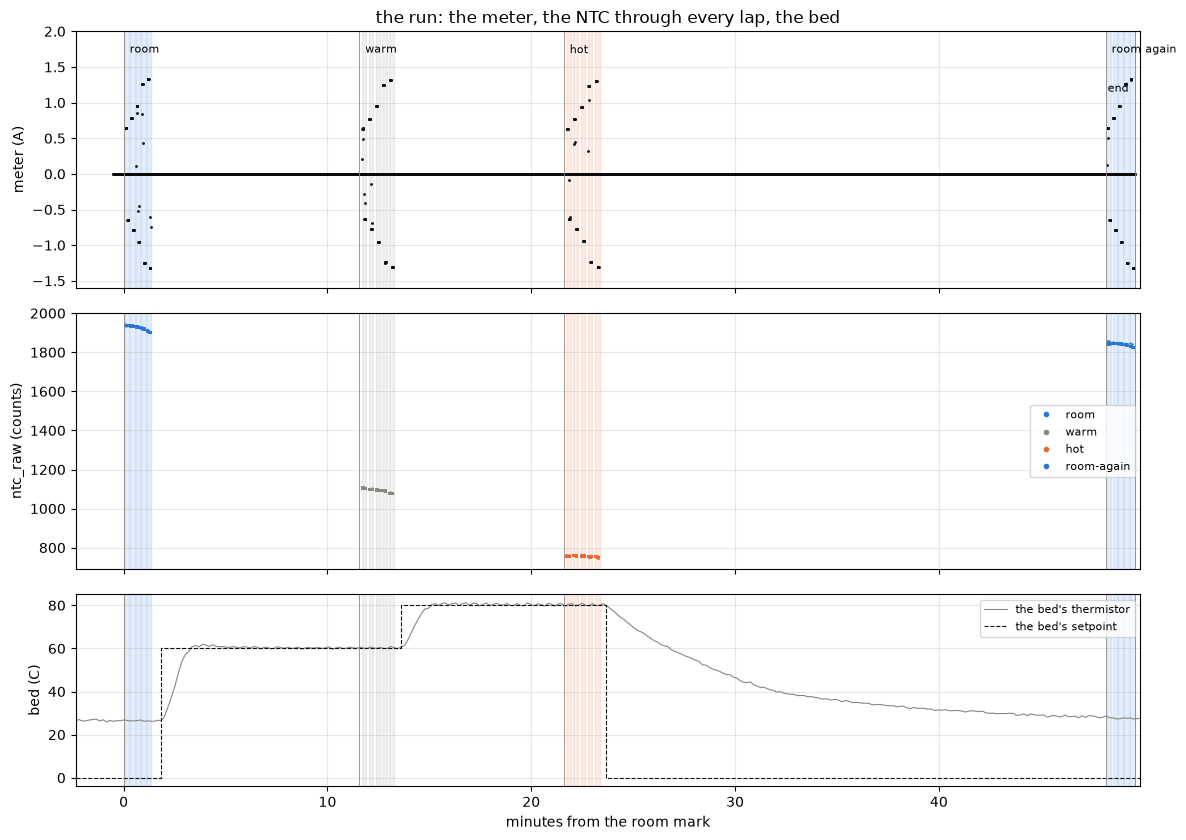

missing rows per lap: {'room': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'warm': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'hot': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, 'room-again': {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}}


In [3]:
SEG_T0 = {0: 0.0, 1: 1.0, 2: 6.0}      # nominal start of each segment inside a lap: 1 s rest, 3 s drive, 2 s rest not streamed, 3 s drive

def lap_trace(p, L, step=200):
    # the rows of one lap thinned to every 10 ms, placed on the host clock at the lap's start plus the segment's nominal offset
    df, meta = tel.load(CAPTURE / p / L["folder"], BOARD)             # checks the sense block against the board entry
    d = df.iloc[::step].copy()
    d["t_host"] = L["t_start"] + d["seg"].map(SEG_T0) + d["tick"] / meta["tick_hz"]
    d["plateau"], d["k"], d["missing"] = p, int(L["k"]), int(tel.gaps(df).sum())
    return d

trace = pd.concat([lap_trace(L["plateau"], L) for _, L in levels.iterrows()], ignore_index=True)
missing = trace.drop_duplicates(["plateau", "k"]).set_index(["plateau", "k"])["missing"]
fig, ax = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.6, 1.6, 1.2]})
ax[0].plot(tm(dmm["t_host"]), dmm["value"], ".", ms=2, color=INK)
for _, L in levels.iterrows():                                        # each lap's sweep window, in the plateau's colour
    for a in ax:
        a.axvspan(tm(L["t_start"]), tm(L["t_end"]), color=COLOR[L["plateau"]], alpha=0.12)
ax[0].set_ylabel("meter (A)")
for p in PLATEAUS:
    g = trace[trace["plateau"] == p]
    ax[1].plot(tm(g["t_host"]), g["ntc_raw"], ".", ms=1.5, color=COLOR[p], label=p)
ax[1].set_ylabel("ntc_raw (counts)"); ax[1].legend(fontsize=8, loc="center right", markerscale=4)
ax[2].plot(tm(heater["t_host"]), heater["bed_c"], "-", lw=0.8, color=MUTED, label="the bed's thermistor")
ax[2].step(tm(heater["t_host"]), heater["target_c"], where="post", lw=0.8, ls="--", color=INK, label="the bed's setpoint")
ax[2].set_ylabel("bed (C)"); ax[2].legend(fontsize=8, loc="upper right")
for a in ax:
    for _, m in marks.iterrows():                                     # the marks
        a.axvline(tm(m["t_host"]), color=MUTED, lw=0.6)
    a.grid(alpha=0.3)
for _, m in marks.iterrows():                                         # the mark names along the top of the first panel, `end` a row lower and to the left of its line
    end = m["mark"] == "end"
    ax[0].text(tm(m["t_host"]) + (-0.3 if end else 0.3), 0.80 if end else 0.95, m["mark"], fontsize=8, va="top", ha="right" if end else "left", transform=ax[0].get_xaxis_transform())
ax[0].set_ylim(-1.6, 2.0); ax[0].set_title("the run: the meter, the NTC through every lap, the bed")
ax[-1].set_xlabel("minutes from the room mark"); ax[-1].set_xlim(tm(heater["t_host"].iloc[0]), tm(heater["t_host"].iloc[-1]))
plt.tight_layout(); plt.show()
print("missing rows per lap:", {p: missing[p].to_dict() for p in PLATEAUS})

The meter reads zero between laps and a stroke each way in every lap, the strokes a little shorter at the warm and hot plateaus. The NTC's count steps down from about 1930 at room to 1100 at warm and 760 at hot, and sits at 1840 at room again, which the next section turns into degrees. The bed sits well over the board at the two heated plateaus, as in ntc-curve, 60 C of bed for about 50 C of board and 80 C for about 63 C, and it sat at 26 to 27 C with its heater off through the room laps, warm from the earlier run, so the first plateau is not the room's 24 C either. No lap of any plateau dropped a row.

## Method

Each plateau's laps give counts over the lap's own torque-off zero against the meter's amps, as in current-scale, and a straight line through its ten points, $n = b + G \, I$, is that plateau's gain $G$ in counts per amp and in-drive offset $b$ in counts. The board temperature of a plateau is the mean of its laps' NTC readings during the drive, converted by the beta equation at the nominal beta from the ntc-curve result, its design conversion, with the spread over the laps as its bracket. The gain at each plateau against the first room plateau, in percent, is the drift, and read through copper's 0.39 % per degree it is the winding temperature a hold would misread by. The torque-off zero of each plateau is read the same way in counts.

The drift per degree is the slope of a line through the four plateaus' drift against their board temperature, with the standard error of that line from the residuals of four points. Two of the four sit near one temperature, so the line's lever arm is the room to hot span and the fourth point mostly reads the return. Two other estimators are run as checks. One pools all forty rows into one model, $n = b + G \, I \, (1 + c \, (T - T_0))$, with one offset for the run and $c$ as the drift per degree, which uses the within-plateau scatter for its error. The other takes each lap's counts over amps against the room lap at the same level and direction, a per-lap ratio that needs no intercept, and reads the drift at each plateau as the mean of ten such ratios with the standard error of that mean.

The meter's class on the 20 A range, 2 % of the reading plus 25 mA, does not enter the drift. A gain error of the meter is the same at every plateau and divides out of a ratio of gains on the same meter in one sitting. What does enter is the meter's repeatability, its 1 mA steps and whatever of the fixed term moves within an hour, and both are inside the fit's residual, so the drift is bounded by the fit's standard error and not by the class. The absolute gain at any plateau carries the class as before.

A plateau temperature through the nominal beta carries ntc-curve's grade. The meter's class there is 1 % of the reading plus 0.5 C, 1.1 C at the hot plateau, and the bed heating the board from below left the top surface, and the thermocouple that graded the curve, under the NTC's copper by about 0.06 C per C the bed sat over the board, 1.1 C at the hot plateau here with the bed 18 C over it. Together that is about 2 C on the hot plateau's temperature, which moves a per-degree slope over the 35 C span by about 6 % and nothing else here. The drift is also drawn against the raw NTC count, which needs no curve at all.

### The lap table

One row per lap and direction, every plateau, the meter joined by its driven stretches.

In [4]:
def ntc_c(raw):
    # the NTC's temperature in degrees C from its raw count, the beta equation at the nominal beta, ntc-curve's design conversion
    return 1 / (1 / 298.15 + np.log(BOARD.ntc_ohm(np.asarray(raw, float)) / BOARD.ntc_r25_ohm) / BETA) - 273.15

tables = {p: laps.table(CAPTURE / p, BOARD, dmm).assign(plateau=p) for p in PLATEAUS}   # the settled means, the rest zero, the meter's median per direction
T = pd.concat(tables.values(), ignore_index=True)
T["counts"] = T["current_raw"] - T["zero"]                            # n, counts over the lap's own rest zero
T["amps"] = T["meter"].abs()                                          # I, the meter's current, unsigned
T["board_c"] = ntc_c(T["ntc_raw"])                                    # the board during that direction's drive
show(T[["plateau", "k", "volts_set", "vsys_read", "dir", "zero", "current_raw", "counts", "current_sd", "meter", "meter_n", "ntc_raw", "board_c"]], n=None)
room = T[T["plateau"] == "room"].set_index(["k", "dir"])
for p in PLATEAUS:                                                    # the load's current at each plateau against room at the same level and direction
    t = T[T["plateau"] == p].set_index(["k", "dir"])
    print(f"{p:10s} {t['amps'].min():.3f} to {t['amps'].max():.3f} A, meter packets per point {t['meter_n'].min()} to {t['meter_n'].max()}, "
          f"current against the room lap at the same level {((t['amps'] / room['amps'] - 1) * 100).mean():+.2f} %, board {t['board_c'].min():.1f} to {t['board_c'].max():.1f} C, "
          f"in-lap sd {t['current_sd'].min():.1f} to {t['current_sd'].max():.1f} counts")

,plateau,k,volts_set,vsys_read,dir,zero,current_raw,counts,current_sd,meter,meter_n,ntc_raw,board_c
0,room,0,3.700,3.698,1,1207.000,1940.974,733.974,1.322,0.641,6,1940.206,27.390
1,room,0,3.700,3.698,-1,1207.000,1938.964,731.964,1.324,-0.641,6,1940.154,27.391
2,room,1,4.500,4.503,1,1207.000,2100.698,893.698,1.448,0.783,6,1938.172,27.436
3,room,1,4.500,4.503,-1,1207.000,2098.118,891.118,1.506,-0.782,6,1936.580,27.471
4,room,2,5.500,5.516,1,1207.000,2301.166,1094.166,1.497,0.958,6,1931.966,27.575
5,room,2,5.500,5.516,-1,1207.000,2298.426,1091.426,1.462,-0.957,7,1929.759,27.624
6,room,3,7.200,7.203,1,1207.000,2640.491,1433.491,2.098,1.256,7,1923.952,27.755
7,room,3,7.200,7.203,-1,1207.000,2635.778,1428.778,2.011,-1.255,6,1919.884,27.846
8,room,4,7.600,7.583,1,1207.000,2717.323,1510.323,2.078,1.327,6,1909.914,28.071
9,room,4,7.600,7.583,-1,1207.000,2712.682,1505.682,2.014,-1.324,7,1904.473,28.193


room       0.641 to 1.327 A, meter packets per point 6 to 7, current against the room lap at the same level +0.00 %, board 27.4 to 28.2 C, in-lap sd 1.3 to 2.1 counts
warm       0.636 to 1.313 A, meter packets per point 6 to 7, current against the room lap at the same level -0.93 %, board 49.2 to 50.1 C, in-lap sd 1.4 to 2.4 counts
hot        0.629 to 1.307 A, meter packets per point 6 to 7, current against the room lap at the same level -1.53 %, board 62.3 to 62.8 C, in-lap sd 1.2 to 2.6 counts
room-again 0.640 to 1.325 A, meter packets per point 6 to 6, current against the room lap at the same level -0.06 %, board 29.5 to 29.9 C, in-lap sd 1.3 to 2.1 counts


Forty points, ten per plateau, 0.63 to 1.33 A. The meter gives six or seven packets per direction, and the current channel's standard deviation inside a lap is 1.2 to 2.6 counts, as in current-scale. The current at a level falls 0.9 % at the warm plateau and 1.5 % at the hot one against room, which is the load warming on the bed, and comes back at room again. The board temperature through the nominal beta is 27.7, 49.5, 62.6 and 29.6 C at the four plateaus, each moving under a degree across its five laps.

## Results

### Gain and offset per plateau

Counts over the lap's own zero against the meter's amps, every lap of every plateau, with one line through all forty points, and under it the residuals from that line by plateau with each plateau's own line dotted through them. The thing to see is the warm and hot points sitting under the room points at the top of the range, which is the quarter percent.

,plateau,board_c,c_lo,c_hi,ntc_raw,gain,gain_se,offset,offset_se,rms,zero,zero_lo,zero_hi,laps,gain_pct,gain_pct_se,copper_c
0,room,27.675,27.390,28.193,1927.506,1134.665,1.938,5.478,1.990,1.447,1207.000,1207.000,1207.000,10,0.000,0.171,0.000
1,warm,49.542,49.165,50.068,1095.512,1132.043,2.053,6.214,2.087,1.514,1209.000,1209.000,1209.000,10,-0.231,0.181,-0.592
2,hot,62.573,62.345,62.807,757.841,1131.630,1.987,5.504,2.010,1.465,1209.000,1208.000,1210.000,10,-0.267,0.176,-0.686
3,room-again,29.624,29.500,29.942,1841.519,1135.059,1.331,5.125,1.366,0.992,1207.200,1207.000,1208.000,10,0.035,0.117,0.089


all forty points: G 1133.5 +/- 1.2 counts/A, b +5.5 +/- 1.2 counts, rms 1.91; current-scale at room 1135.0 +/- 1.2, b +5.3
room       board 27.7 C  G 1134.7 +/- 1.9 counts/A (+0.00 % against room, +/- 0.17)  b +5.5 +/- 2.0 counts  rms 1.45  zero 1207.0 (1207 to 1207)  copper +0.00 C
warm       board 49.5 C  G 1132.0 +/- 2.1 counts/A (-0.23 % against room, +/- 0.18)  b +6.2 +/- 2.1 counts  rms 1.51  zero 1209.0 (1209 to 1209)  copper -0.59 C
hot        board 62.6 C  G 1131.6 +/- 2.0 counts/A (-0.27 % against room, +/- 0.18)  b +5.5 +/- 2.0 counts  rms 1.46  zero 1209.0 (1208 to 1210)  copper -0.69 C
room-again board 29.6 C  G 1135.1 +/- 1.3 counts/A (+0.03 % against room, +/- 0.12)  b +5.1 +/- 1.4 counts  rms 0.99  zero 1207.2 (1207 to 1208)  copper +0.09 C


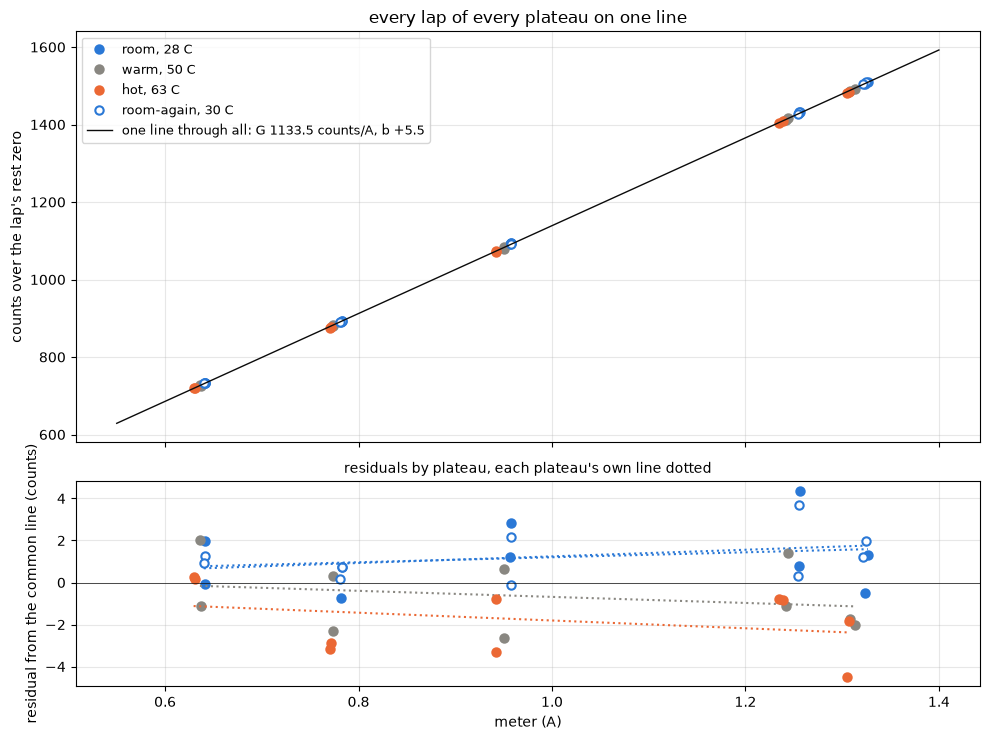

In [5]:
rows = []
for p in PLATEAUS:
    t = T[T["plateau"] == p]
    f = laps.line(t["amps"], t["counts"])                             # that plateau's line, with the standard errors
    rows.append({"plateau": p, "board_c": t["board_c"].mean(), "c_lo": t["board_c"].min(), "c_hi": t["board_c"].max(), "ntc_raw": t["ntc_raw"].mean(),
                 "gain": f["slope"], "gain_se": f["slope_se"], "offset": f["intercept"], "offset_se": f["intercept_se"], "rms": f["rms"],
                 "zero": t["zero"].mean(), "zero_lo": t["zero"].min(), "zero_hi": t["zero"].max(), "laps": len(t)})
P = pd.DataFrame(rows)
P["gain_pct"] = (P["gain"] / P["gain"].iloc[0] - 1) * 100             # the drift against the first room plateau
P["gain_pct_se"] = P["gain_se"] / P["gain"] * 100                     # each plateau's own standard error, in percent
P["copper_c"] = P["gain_pct"] / COPPER_PCT_PER_C                      # that drift read as winding temperature
show(P, n=None)
fit_all = laps.line(T["amps"], T["counts"])                           # one line through all forty points, the reference for the residual panel
T["resid"] = T["counts"] - (fit_all["slope"] * T["amps"] + fit_all["intercept"])
print(f"all forty points: G {fit_all['slope']:.1f} +/- {fit_all['slope_se']:.1f} counts/A, b {fit_all['intercept']:+.1f} +/- {fit_all['intercept_se']:.1f} counts, rms {fit_all['rms']:.2f}; "
      f"current-scale at room {CS['counts_per_a']['value']:.1f} +/- {CS['counts_per_a']['value'] - CS['counts_per_a']['lo']:.1f}, b {CS['drive_offset_counts']['value']:+.1f}")
for _, r in P.iterrows():
    print(f"{r['plateau']:10s} board {r['board_c']:.1f} C  G {r['gain']:.1f} +/- {r['gain_se']:.1f} counts/A ({r['gain_pct']:+.2f} % against room, +/- {r['gain_pct_se']:.2f})  "
          f"b {r['offset']:+.1f} +/- {r['offset_se']:.1f} counts  rms {r['rms']:.2f}  zero {r['zero']:.1f} ({r['zero_lo']:.0f} to {r['zero_hi']:.0f})  copper {r['copper_c']:+.2f} C")
fig, ax = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
x = np.linspace(0.55, 1.4, 10)
for p in PLATEAUS:
    t = T[T["plateau"] == p]; r = P[P["plateau"] == p].iloc[0]
    kw = dict(ls="none", marker="o", ms=6, color=COLOR[p], mfc=FACE[p], mew=1.5)
    ax[0].plot(t["amps"], t["counts"], label=f"{p}, {r['board_c']:.0f} C", **kw)
    ax[1].plot(t["amps"], t["resid"], **kw)
    xp = np.linspace(t["amps"].min(), t["amps"].max(), 5)             # that plateau's own line, as a residual from the common one
    ax[1].plot(xp, r["gain"] * xp + r["offset"] - (fit_all["slope"] * xp + fit_all["intercept"]), ":", color=COLOR[p], lw=1.5)
ax[0].plot(x, fit_all["slope"] * x + fit_all["intercept"], "-", color=INK, lw=1, label=f"one line through all: G {fit_all['slope']:.1f} counts/A, b {fit_all['intercept']:+.1f}")
ax[0].set_ylabel("counts over the lap's rest zero"); ax[0].legend(fontsize=9); ax[0].grid(alpha=0.3); ax[0].set_title("every lap of every plateau on one line")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_ylabel("residual from the common line (counts)"); ax[1].set_xlabel("meter (A)"); ax[1].grid(alpha=0.3)
ax[1].set_title("residuals by plateau, each plateau's own line dotted", fontsize=10)
plt.tight_layout(); plt.show()

The forty points lie on one line to the eye, and one line through all of them gives 1133.5 +/- 1.2 counts per amp with an offset of +5.5 counts and a residual of 1.9 counts rms, the current-scale numbers again with a little more scatter. The residual panel is where the plateaus part. The room and room-again points sit one to two counts over the common line at 1.3 A and the warm and hot points two to four counts under it, with the dotted lines fanning out from near zero at 0.6 A, which is a gain difference and not an offset. Each plateau's own line gives 1134.7 +/- 1.9 at room, 1132.0 +/- 2.1 at warm, 1131.6 +/- 2.0 at hot and 1135.1 +/- 1.3 at room again, a fall of 0.23 and 0.27 % at the two heated plateaus and a return to +0.03 % at room again. The offsets are +5.5, +6.2, +5.5 and +5.1 counts, each +/- 2, so the offset does not move with temperature to within its error, and the zero is 1207 counts at the two room plateaus and 1209 at the two heated ones.

### The drift against board temperature

The gain's drift at each plateau against the board temperature with its own standard error, the line through the four points, and a band of two degrees of copper for scale. The same drift against the raw NTC count, which needs no curve. And the torque-off zero against board temperature. The thing to see is whether the drift follows the temperature and comes back with it.

line through the four plateaus: gain -0.0090 +/- 0.0017 % per C over 28 to 63 C, rms 0.035 %; zero +0.062 +/- 0.015 counts per C; against the raw count +0.0266 +/- 0.0041 % per 100 counts
pooled model over all forty rows, one offset: G 1134.7 +/- 0.9 counts/A at 27.7 C, b +5.5 +/- 0.9, drift -0.0080 +/- 0.0014 % per C, rms 1.37 counts
per-lap ratio against the room lap at the same level: room +0.00 +/- 0.00 %, warm -0.15 +/- 0.03 %, hot -0.25 +/- 0.05 %, room-again +0.00 +/- 0.03 %
room again against room: +0.03 +/- 0.21 %; hot against room -0.27 % over 34.9 C, -0.69 C of copper; per degree of board -0.0230 C of winding
a plateau temperature's own uncertainty: the meter's class 1.1 C at the hot plateau and the bed gradient 1.1 C with the bed 18 C over the board, together 2.2 C on a 34.9 C span, about 6 % on the slope


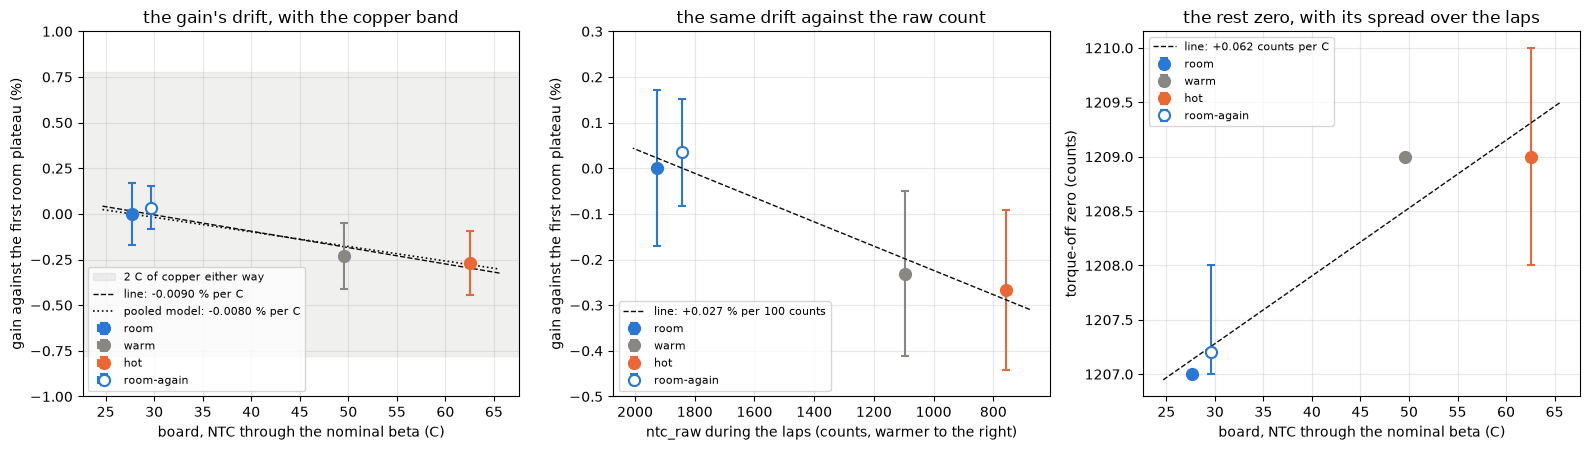

In [6]:
g = laps.line(P["board_c"], P["gain_pct"])                            # the drift per degree, a line through the four plateaus
z = laps.line(P["board_c"], P["zero"])                                # the zero per degree, the same way
rl = laps.line(P["ntc_raw"], P["gain_pct"])                            # the drift per raw count, no curve in it
T0_C = P["board_c"].iloc[0]
X = np.column_stack([np.ones(len(T)), T["amps"], T["amps"] * (T["board_c"] - T0_C)])   # the pooled model: n = b + G I + G c I (T - T0)
coef, *_ = np.linalg.lstsq(X, T["counts"].to_numpy(float), rcond=None)
res = T["counts"].to_numpy(float) - X @ coef
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (res @ res) / (len(T) - 3))
pooled, pooled_se = coef[2] / coef[1] * 100, se[2] / coef[1] * 100     # c in percent per degree, with its standard error
ratio = {}
for p in PLATEAUS:                                                    # each lap's counts per amp against the room lap at the same level and direction
    t = T[T["plateau"] == p].set_index(["k", "dir"])
    q = ((t["counts"] / t["amps"]) / (room["counts"] / room["amps"]) - 1) * 100
    ratio[p] = (q.mean(), q.std() / np.sqrt(len(q)))
back = P["gain_pct"].iloc[3]; back_se = np.hypot(P["gain_pct_se"].iloc[0], P["gain_pct_se"].iloc[3])   # room again against room, both errors in it
span = P["board_c"].iloc[2] - P["board_c"].iloc[0]
print(f"line through the four plateaus: gain {g['slope']:+.4f} +/- {g['slope_se']:.4f} % per C over {P['board_c'].min():.0f} to {P['board_c'].max():.0f} C, rms {g['rms']:.3f} %; "
      f"zero {z['slope']:+.3f} +/- {z['slope_se']:.3f} counts per C; against the raw count {rl['slope'] * 100:+.4f} +/- {rl['slope_se'] * 100:.4f} % per 100 counts")
print(f"pooled model over all forty rows, one offset: G {coef[1]:.1f} +/- {se[1]:.1f} counts/A at {T0_C:.1f} C, b {coef[0]:+.1f} +/- {se[0]:.1f}, drift {pooled:+.4f} +/- {pooled_se:.4f} % per C, rms {np.sqrt((res ** 2).mean()):.2f} counts")
print("per-lap ratio against the room lap at the same level: " + ", ".join(f"{p} {m:+.2f} +/- {s:.2f} %" for p, (m, s) in ratio.items()))
print(f"room again against room: {back:+.2f} +/- {back_se:.2f} %; hot against room {P['gain_pct'].iloc[2]:+.2f} % over {span:.1f} C, "
      f"{P['copper_c'].iloc[2]:+.2f} C of copper; per degree of board {g['slope'] / COPPER_PCT_PER_C:+.4f} C of winding")
hot_laps = levels[levels["plateau"] == "hot"]
bed_hot = heater[heater["t_host"].between(hot_laps["t_start"].min(), hot_laps["t_end"].max())]["bed_c"].mean()   # the bed's thermistor through the hot laps
class_hot = DMM["accuracy"]["temp_c"]["pct"]["value"] / 100 * P["board_c"].iloc[2] + DMM["accuracy"]["temp_c"]["fixed"]["value"]   # the meter's class at the hot plateau, the grade behind the curve
grad_hot = NC["gradient_c_per_c"]["value"] * (bed_hot - P["board_c"].iloc[2])    # the bed gradient ntc-curve names, per C the bed sits over the board
print(f"a plateau temperature's own uncertainty: the meter's class {class_hot:.1f} C at the hot plateau and the bed gradient {grad_hot:.1f} C with the bed "
      f"{bed_hot - P['board_c'].iloc[2]:.0f} C over the board, together {class_hot + grad_hot:.1f} C on a {span:.1f} C span, about {(class_hot + grad_hot) / span * 100:.0f} % on the slope")
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
tt = np.linspace(P["board_c"].min() - 3, P["board_c"].max() + 3, 10)
ax[0].axhspan(-COPPER_PCT_PER_C * 2, COPPER_PCT_PER_C * 2, color=MUTED, alpha=0.12, label="2 C of copper either way")
ax[0].plot(tt, g["slope"] * tt + g["intercept"], "--", color=INK, lw=1, label=f"line: {g['slope']:+.4f} % per C")
ax[0].plot(tt, pooled * (tt - T0_C), ":", color=INK, lw=1.2, label=f"pooled model: {pooled:+.4f} % per C")
rr = np.linspace(P["ntc_raw"].min() - 80, P["ntc_raw"].max() + 80, 10)
for _, p_ in P.iterrows():
    p = p_["plateau"]; kw = dict(fmt="o", ms=8, color=COLOR[p], mfc=FACE[p], mew=1.5, capsize=3, label=p)
    ax[0].errorbar(p_["board_c"], p_["gain_pct"], yerr=p_["gain_pct_se"], xerr=[[p_["board_c"] - p_["c_lo"]], [p_["c_hi"] - p_["board_c"]]], **kw)
    ax[1].errorbar(p_["ntc_raw"], p_["gain_pct"], yerr=p_["gain_pct_se"], **kw)
    ax[2].errorbar(p_["board_c"], p_["zero"], yerr=[[p_["zero"] - p_["zero_lo"]], [p_["zero_hi"] - p_["zero"]]], **kw)
ax[1].plot(rr, rl["slope"] * rr + rl["intercept"], "--", color=INK, lw=1, label=f"line: {rl['slope'] * 100:+.3f} % per 100 counts")
ax[2].plot(tt, z["slope"] * tt + z["intercept"], "--", color=INK, lw=1, label=f"line: {z['slope']:+.3f} counts per C")
ax[0].set_ylim(-1.0, 1.0); ax[0].set_xlabel("board, NTC through the nominal beta (C)"); ax[0].set_ylabel("gain against the first room plateau (%)"); ax[0].set_title("the gain's drift, with the copper band")
ax[1].set_ylim(-0.5, 0.3); ax[1].invert_xaxis(); ax[1].set_xlabel("ntc_raw during the laps (counts, warmer to the right)"); ax[1].set_ylabel("gain against the first room plateau (%)"); ax[1].set_title("the same drift against the raw count")
ax[2].set_xlabel("board, NTC through the nominal beta (C)"); ax[2].set_ylabel("torque-off zero (counts)"); ax[2].set_title("the rest zero, with its spread over the laps")
for a, loc in zip(ax, ("lower left", "lower left", "upper left")):
    a.grid(alpha=0.3); a.legend(fontsize=8, loc=loc)
plt.tight_layout(); plt.show()

Left, the gain falls as the board warms and comes back when it cools, with the two heated plateaus at -0.23 and -0.27 % and the two room plateaus within 0.04 % of each other. The line through the four gives -0.0090 +/- 0.0017 % per C over 28 to 63 C, and the whole excursion sits well inside the band of two degrees of copper, at -0.69 C of winding at the hot plateau. The middle panel reads the same thing off the raw count, +0.027 % per 100 counts with the count falling as the board warms, so the finding does not lean on the curve. The pooled model's dotted line sits on the four-point line in the left panel. Right, the zero sits at 1207 counts at both room plateaus and 1209 at both heated ones, +0.06 counts per C, about 2 counts over the span, which is 1.8 mA at this gain.

The checks agree with the line. The pooled model over all forty rows with one offset gives -0.0080 +/- 0.0014 % per C with a residual of 1.4 counts rms, the within-plateau noise. The per-lap ratios against the room lap at the same level, zero at room by construction, give -0.15 +/- 0.03 % at warm, -0.25 +/- 0.05 % at hot and +0.00 +/- 0.03 % at room again. That last estimator needs no intercept and puts the hot plateau five standard errors under room, so the fall is in the data with high confidence, and its return at room again puts it with the temperature and not with the hour. Its size is a quarter percent over about 35 C of board, with the four-point line's standard error of 0.002 % per C as the bracket and about 6 % more on top from the plateau temperatures' own uncertainty, the meter's class and the bed gradient behind ntc-curve's grade. The per-plateau gains each carry a standard error of 0.17 to 0.18 %, which is most of the signal, so one plateau on its own does not read the drift and the four together do.

| Candidate for the quarter percent | What the data says | Confidence |
|---|---|---|
| The amplifier's gain, its two resistors and the op-amp, moving with temperature | A sister board's amplifier alone, read across the shunt pads, drifted a quarter percent over 28 to 60 C in the one-time characterization current-scale cites. The whole chain here drifts the same quarter percent over 28 to 63 C with the shunt in the loop. | Leading. If both hold, the shunt's share is inside the error. The `rs1` route at one hot plateau reads the amplifier alone on this board. |
| The shunt's own temperature coefficient | A thick-film 60 mOhm part can move 100 to 200 ppm per C, 0.3 to 0.6 % over this span, a metal part under 0.15 %. The chain's drift leaves room for a small one of either sign once the amplifier's is taken out. | Possible. Not separated here. The same `rs1` route separates it. |
| The ADC's reference, VDD, moving with temperature | The zero is a share of VDD through the pull-ups and moved 2 counts in 1207, +0.17 %, in the wrong direction for a falling gain. The laps carry no `vref_raw`. | Unlikely as the whole. A lap chunk that streams `vref_raw` reads it directly. |
| The meter reading differently at the warm and hot plateaus | The meter sat at room throughout, on one range, and its class is a fixed share of the reading. Its 1 mA steps are 0.08 % of a 1.3 A reading. | Unlikely. A second meter in the loop, or the shunt's millivolts beside the amps, checks it. |
| The load's 1 % fall in current | Moves the x axis, not the line. The per-level ratio at the same level, which does see the 1 %, is taken against the meter's amps and not the level. | Does not enter. |
| The offset moving with temperature, read as gain over a short current range | The four offsets agree within their 2 count errors, and the pooled model with one offset gives the same drift as the lines with free offsets. | Unlikely. |

### The NTC under drive

The ntc-curve notebook left open whether the board's own heat moves the NTC. Each lap here has a one second torque-off rest before its first drive and the NTC in every row at the control rate, so the count's change from that rest through the two driven segments is the drive's heat reaching the NTC, and the rest of the next lap says whether it kept moving in the gap. Left, the raw count through the room plateau's five laps on the host clock, the driven segments shaded, each lap's segments placed at their nominal offsets inside the sweep. Right, the move within each lap, the last 300 ms of the second drive against the rest before the first, in degrees through the nominal beta, against the lap's current, for all four plateaus. The thing to see is whether the count falls while the bridge drives and by how much.

,plateau,k,volts_set,amps,rest,rest_sd,drive_1,drive_2,end,minutes,in_lap_counts,in_lap_c,gap_counts
0,room,0,3.700,0.641,1940.049,0.966,1940.207,1940.154,1940.021,0.065,-0.028,0.001,-1.438
1,room,1,4.500,0.782,1938.583,0.984,1938.172,1936.581,1936.026,0.333,-2.556,0.057,-3.381
2,room,2,5.500,0.958,1932.646,1.005,1931.966,1929.759,1929.099,0.606,-3.547,0.080,-4.090
3,room,3,7.200,1.256,1925.008,1.002,1923.952,1919.884,1918.665,0.872,-6.343,0.143,-7.370
4,room,4,7.600,1.325,1911.295,0.888,1909.915,1904.474,1902.820,1.150,-8.475,0.191,NaN
5,warm,0,3.700,0.637,1107.589,0.713,1107.018,1106.063,1105.467,11.688,-2.123,0.069,-5.087
6,warm,1,4.500,0.774,1100.380,0.681,1100.651,1101.150,1101.764,12.020,1.384,-0.045,-3.796
7,warm,2,5.500,0.950,1097.968,0.773,1097.068,1096.078,1095.763,12.360,-2.206,0.072,-1.060
8,warm,3,7.200,1.243,1094.703,0.639,1094.132,1093.478,1093.091,12.693,-1.612,0.053,-12.514
9,warm,4,7.600,1.311,1080.577,0.694,1079.919,1079.569,1079.611,13.036,-0.965,0.032,NaN


room       rest before the first lap 1940, before the last 1911 counts (+0.65 C over 1.1 min); within the 7.6 V lap -8.5 counts = +0.19 C; through the gaps -1.4, -3.4, -4.1, -7.4 counts
warm       rest before the first lap 1108, before the last 1081 counts (+0.89 C over 1.3 min); within the 7.6 V lap -1.0 counts = +0.03 C; through the gaps -5.1, -3.8, -1.1, -12.5 counts
hot        rest before the first lap 759, before the last 757 counts (+0.06 C over 1.4 min); within the 7.6 V lap -6.4 counts = +0.30 C; through the gaps +4.2, -2.0, -2.9, +0.5 counts
room-again rest before the first lap 1843, before the last 1832 counts (+0.25 C over 1.1 min); within the 7.6 V lap -5.8 counts = +0.13 C; through the gaps +0.3, -0.5, -2.5, -5.7 counts
the curve's slope: -45 counts per C at room, -22 at the hot plateau; the rest's sd 0.6 to 1.0 counts


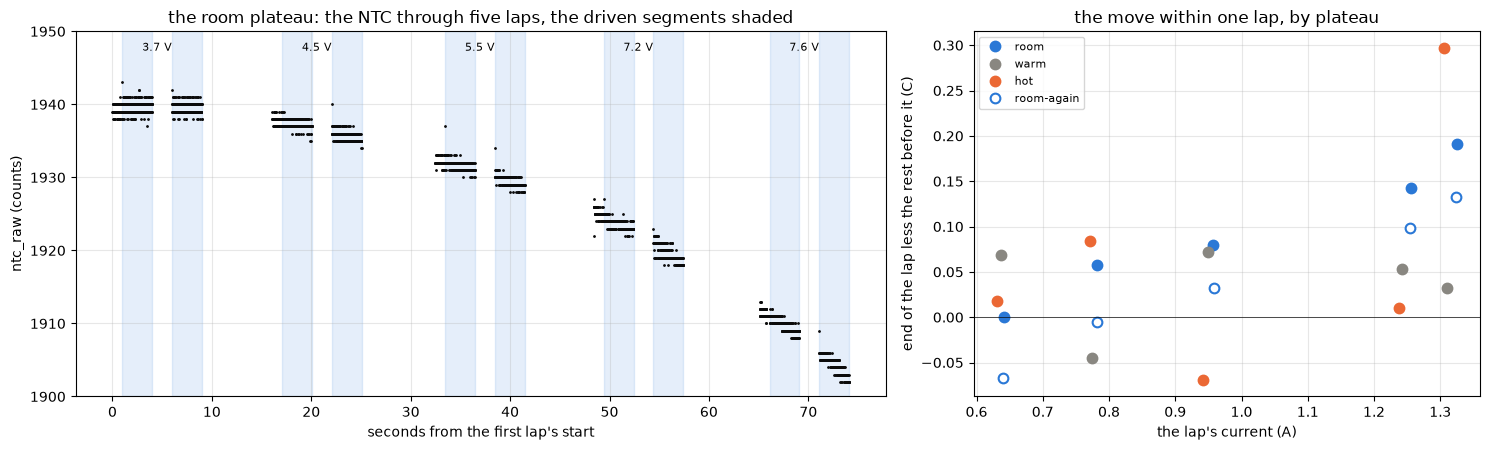

In [7]:
rows = []
for _, L in levels.iterrows():
    df, meta = tel.load(CAPTURE / L["plateau"] / L["folder"])
    b = tel.baseline(df)                                              # the second half of the rest before the lap
    s2 = df[df["seg"] == 2]
    rows.append({"plateau": L["plateau"], "k": int(L["k"]), "volts_set": L["volts_set"], "amps": T[(T["plateau"] == L["plateau"]) & (T["k"] == L["k"])]["amps"].mean(),
                 "rest": b["ntc_raw"].mean(), "rest_sd": b["ntc_raw"].std(), "drive_1": df[df["seg"] == 1]["ntc_raw"].mean(), "drive_2": s2["ntc_raw"].mean(),
                 "end": s2["ntc_raw"].iloc[-6000:].mean(), "minutes": tm(L["t_start"])})   # the last 300 ms of the second drive
N = pd.DataFrame(rows)
N["in_lap_counts"] = N["end"] - N["rest"]                             # the move within the lap, counts
N["in_lap_c"] = ntc_c(N["end"]) - ntc_c(N["rest"])                    # the same in degrees, the curve's slope at that count
N["gap_counts"] = N.groupby("plateau")["rest"].shift(-1) - N["end"]   # the next lap's rest less this lap's end: the move through the gap with the bridge off
show(N, n=None)
for p in PLATEAUS:
    n_ = N[N["plateau"] == p]
    print(f"{p:10s} rest before the first lap {n_['rest'].iloc[0]:.0f}, before the last {n_['rest'].iloc[-1]:.0f} counts ({ntc_c(n_['rest'].iloc[-1]) - ntc_c(n_['rest'].iloc[0]):+.2f} C over {n_['minutes'].iloc[-1] - n_['minutes'].iloc[0]:.1f} min); "
          f"within the 7.6 V lap {n_['in_lap_counts'].iloc[-1]:+.1f} counts = {n_['in_lap_c'].iloc[-1]:+.2f} C; through the gaps " + ", ".join(f"{v:+.1f}" for v in n_['gap_counts'].dropna()) + " counts")
print(f"the curve's slope: {1 / (ntc_c(1929) - ntc_c(1928)):.0f} counts per C at room, {1 / (ntc_c(759) - ntc_c(758)):.0f} at the hot plateau; the rest's sd {N['rest_sd'].min():.1f} to {N['rest_sd'].max():.1f} counts")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
gr = trace[trace["plateau"] == "room"]
for _, L in levels[levels["plateau"] == "room"].iterrows():        # the driven segments of each lap, shaded
    for s in (1, 2):
        ax[0].axvspan(L["t_start"] + SEG_T0[s] - levels["t_start"].min(), L["t_start"] + SEG_T0[s] + 3 - levels["t_start"].min(), color=BLUE, alpha=0.12)
    ax[0].text(L["t_start"] + 4.5 - levels["t_start"].min(), 0.97, f"{L['volts_set']:g} V", fontsize=8, ha="center", va="top", transform=ax[0].get_xaxis_transform())
ax[0].plot(gr["t_host"] - levels["t_start"].min(), gr["ntc_raw"], ".", ms=2, color=INK)
ax[0].set_ylim(gr["ntc_raw"].min() - 2, gr["ntc_raw"].max() + 7)     # headroom for the level names over the first lap
ax[0].set_xlabel("seconds from the first lap's start"); ax[0].set_ylabel("ntc_raw (counts)"); ax[0].set_title("the room plateau: the NTC through five laps, the driven segments shaded"); ax[0].grid(alpha=0.3)
for p in PLATEAUS:
    n_ = N[N["plateau"] == p]
    ax[1].plot(n_["amps"], n_["in_lap_c"], ls="none", marker="o", ms=7, color=COLOR[p], mfc=FACE[p], mew=1.5, label=p)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlabel("the lap's current (A)"); ax[1].set_ylabel("end of the lap less the rest before it (C)")
ax[1].set_title("the move within one lap, by plateau"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

At the room plateau the count falls through every driven segment and more at the higher levels, 8.5 counts within the 7.6 V lap, which is 0.19 C at the curve's slope there, and it keeps falling through the gap after each lap with the bridge off, 1 to 7 counts and more after the higher levels, so the heat reaches the NTC a few seconds behind the drive. From the rest before the first lap to the rest before the last the count falls 29 counts, 0.65 C, over 80 s of laps. The room-again plateau shows the same shape at 0.13 C within the 7.6 V lap and 0.25 C across the laps. At the two heated plateaus the move within a lap is a few counts of either sign at most levels, with the hot 7.6 V lap at 0.30 C, and the bed's regulation is cycling by a degree every ten seconds under the board there, so the drive's signal is in the bed's noise at warm and partly out of it at hot. One thing in the warm plateau does not fit either story. Its rest before the 7.6 V lap sits 12.5 counts under the end of the 7.2 V lap, 0.41 C in seven seconds with the bridge off, where the other gaps at that plateau move 1 to 5 counts. It is noted and not explained, and the host's one register read during the warm laps is the only other thing that happened there.

So the board's own heat under drive does move the NTC, by a few tenths of a degree per 9 W lap at room and up to two thirds of a degree over five laps, with a lag of seconds, with high confidence at the room plateaus. The ntc-curve capture ran with the bridge off, so none of that is in its curve, and a board temperature read from the NTC during or just after a hard drive sits a few tenths over the rest reading. Where the heat comes from is open. At 1.3 A the feed diode drops about 0.25 V for 0.3 W, the bridge and the shunt together about as much, all on the board, and the load's 9 W went into the bed under the board. The experiment that separates them is under Open questions.

### The results file

The gain's drift per degree from the line through the four plateaus with its standard error as the bounds, the pooled model's drift beside it, the zero's drift per degree, the largest drift, the copper it reads as, the range covered, the return at room again, and the NTC's move under drive. Beside them each plateau's board temperature with its spread over the laps, raw count, gain, offset, zero and drift.

In [8]:
q = results.quantity
plateaus = {r["plateau"]: {"board_c": q(r["board_c"], r["c_lo"], r["c_hi"], "C"), "ntc_raw": q(r["ntc_raw"], unit="counts"),
                           "gain_counts_per_a": q(r["gain"], r["gain"] - r["gain_se"], r["gain"] + r["gain_se"], "counts/A"),
                           "offset_counts": q(r["offset"], r["offset"] - r["offset_se"], r["offset"] + r["offset_se"], "counts"),
                           "zero_counts": q(r["zero"], r["zero_lo"], r["zero_hi"], "counts"), "gain_pct": q(r["gain_pct"], r["gain_pct"] - r["gain_pct_se"], r["gain_pct"] + r["gain_pct_se"], "%"),
                           "residual_rms_counts": q(r["rms"], unit="counts")} for _, r in P.iterrows()}
n_room = N[N["plateau"].isin(["room", "room-again"])]
over_laps = {p: ntc_c(N[N["plateau"] == p]["rest"].iloc[-1]) - ntc_c(N[N["plateau"] == p]["rest"].iloc[0]) for p in ("room", "room-again")}   # first rest to last rest, in degrees
results.write("1-board", "opamp-temperature", CAPTURE, pair=BOARD.key,
              notes=f"DC laps on the bare load at four plateaus of a printer bed, the load on the bed too, meter route {route} on the 20 A range at room; one line per plateau "
                    "through counts over the lap's own zero against the meter's amps; gain_drift_pct_per_c is the line through the four plateaus' gain_pct against "
                    "the board NTC through ntc-curve's beta_nominal, its design conversion, with its standard error as the bounds, gain_drift_pooled_pct_per_c the one-offset "
                    "model over all forty rows; a plateau's board_c is the mean over its laps' drives with the spread over the laps as lo/hi, and beyond that it carries "
                    f"ntc-curve's grade, the meter's class of 1 % + 0.5 C and the bed gradient, {grad_hot:.1f} C at the hot plateau; "
                    "gain_drift_max_pct is the hot plateau against room; reversibility_pct is room-again against room with both errors; ntc_move_in_lap_c is the "
                    "NTC's fall through the 7.6 V lap at the room plateaus, ntc_move_over_laps_c the fall from the first lap's rest to the last's there",
              gain_drift_pct_per_c=q(g["slope"], g["slope"] - g["slope_se"], g["slope"] + g["slope_se"], "%/C"),
              gain_drift_pooled_pct_per_c=q(pooled, pooled - pooled_se, pooled + pooled_se, "%/C"),
              gain_drift_per_100_counts_pct=q(rl["slope"] * 100, (rl["slope"] - rl["slope_se"]) * 100, (rl["slope"] + rl["slope_se"]) * 100, "%/100 counts"),
              zero_drift_counts_per_c=q(z["slope"], z["slope"] - z["slope_se"], z["slope"] + z["slope_se"], "counts/C"),
              gain_drift_max_pct=q(P["gain_pct"].iloc[2], P["gain_pct"].iloc[2] - P["gain_pct_se"].iloc[2], P["gain_pct"].iloc[2] + P["gain_pct_se"].iloc[2], "%"),
              copper_error_max_c=q(P["copper_c"].iloc[2], unit="C"),
              copper_error_c_per_c=q(g["slope"] / COPPER_PCT_PER_C, unit="C/C"),
              range_c=q(P["board_c"].max(), P["board_c"].min(), P["board_c"].max(), "C"),
              reversibility_pct=q(back, back - back_se, back + back_se, "%"),
              ntc_move_in_lap_c=q(n_room[n_room["volts_set"] == 7.6]["in_lap_c"].mean(), n_room[n_room["volts_set"] == 7.6]["in_lap_c"].min(), n_room[n_room["volts_set"] == 7.6]["in_lap_c"].max(), "C"),
              ntc_move_over_laps_c=q(over_laps["room"], min(over_laps.values()), max(over_laps.values()), "C"),
              plateaus=plateaus)

PosixPath('stages/1-board/opamp-temperature/results/dev-v006-2A-D.json')

## Limitations

- On the ammeter route the meter reads the whole loop's current, so the drift is the chain's as a whole, the shunt's own temperature coefficient in it with the amplifier's. The `rs1` route takes the shunt out and was not run in this sitting.
- The load sat on the heated bed, against the procedure. Its current fell 1 to 1.5 % at the heated plateaus, which the fit against the meter's amps does not see, and its 9 W per lap went into the bed under the board, which the NTC section does not separate from the board's own heat.
- Four plateaus, two of them near room, over 28 to 63 C. The line through four points has two degrees of freedom and its standard error is what four points give. The per-plateau gains carry 0.17 % each, the size of the signal, and the drift is read from the four together and the per-lap ratios, not from any one plateau.
- A plateau temperature through the nominal beta carries ntc-curve's grade, the meter's class of 1 % plus 0.5 C, 1.1 C at the hot plateau, and the bed gradient that notebook names, the top surface under the NTC's copper by about 1.1 C with the bed 18 C over the board, about 2 C together and about 6 % on the per-degree slope. The drift against the raw count is free of it.
- The first plateau sat at 28 C by the NTC, not at the room's 24 C, since the bed was still warm from the earlier run, and the room-again plateau at 30 C, so the span is 35 C and the lowest temperature a servo meets is not in it.
- The hot plateau was held eight minutes from the bed's step and settled at a raw count of 758, against 730 at ntc-curve's hot plateau with the same setpoint held longer. The board moved under a degree across each plateau's laps.
- A host process read the NTC register once during the warm plateau's laps, a watch loop that was then stopped. Every segment of every lap reports no missing rows and no garbled bytes, so no harm is seen, and the warm plateau's gain sits between room and hot as expected. The 12 count step in that plateau's last rest is noted in the NTC section and stays unexplained.
- The meter bounds every absolute gain at 2 % plus 25 mA. The drift between plateaus is bounded by the fit's standard error, as said in the method, on the assumption that the meter's own gain held through the hour, which the room-again return supports and does not prove.
- One board, one run. The run to run spread of the drift is not known.

## Open questions

- Whether the quarter percent is the amplifier's or the shunt's. The `rs1` route, the meter on millivolts across the shunt pads, at room and at one hot plateau in the same sitting reads the amplifier alone to 0.1 %. A drift there of the same quarter percent puts it in the amplifier, and a flat reading puts it in the shunt.
- Whether the drift is linear in temperature or settles. A longer hot soak, the laps repeated every ten minutes at one setpoint, says whether the gain keeps moving once the NTC has stopped, which would point to a part warming slower than the NTC does.
- Where the heat that moves the NTC under drive comes from. The same laps with the load off the bed on longer leads, the bed off, and the NTC streamed for a minute after the last lap, separate the load's heat through the bed from the board's own and give the lag directly. A swap board without the feed diode, or the rail fed past the diode, takes the diode's share out.
- The run to run spread. A repeat of this capture on the same rig, with the `rs1` route in the same sitting, gives it.
- The drift below room. A plateau with the board cooled toward 10 C, a cold pack or a cold room, extends the line to the low end a servo meets.

## Conclusion

The current chain's gain on board D falls 0.23 % at 50 C and 0.27 % at 63 C against 28 C, and comes back to +0.03 % at 30 C, so the drift is the temperature's and not the hour's, with high confidence from the per-lap ratios, which put the hot plateau five standard errors under room. The line through the four plateaus gives -0.0090 +/- 0.0017 % per C, the pooled model over all forty rows -0.0080 +/- 0.0014, and the same reading against the raw count is 0.027 % per 100 counts. Read as copper, the whole excursion is -0.7 C of winding temperature over 35 C of board, under a degree, and the winding thermometer's ratio over a hold that warms the board by ten degrees reads the winding 0.23 C cold from the amplifier alone. The in-drive offset is +5 to +6 counts at every plateau and does not move with temperature within its 2 count error. The torque-off zero moves +0.06 counts per C, 2 counts over the span, which a zero taken at rest before each drive follows.

The board's own heat under drive moves the NTC, by 0.19 C through one 9 W lap at room and 0.65 C from the first lap's rest to the last over five laps, with a lag of seconds, which answers ntc-curve's question and puts a few tenths of a degree between the NTC during a hard drive and the board at rest.

Later stages take `gain_drift_pct_per_c` from the result file for a board temperature correction if one is ever wanted, and more likely take the finding as a bound, a quarter percent over the range a board meets on a bench, with the amplifier as the leading owner of it and the shunt not yet separated, which the `rs1` route at one hot plateau settles.